# SOLUCIÓN (docente) · Pacientes y diabetes
Versión resuelta de la práctica con alumnos. Dataset: `datasets/pacientes_diabetes.csv`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_auc_score, RocCurveDisplay, log_loss)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Carga y exploración de datos
Primero miramos qué tenemos: filas, columnas, tipos, **valores faltantes** y cómo se distribuyen las variables.

In [2]:
RUTA = Path("datasets/pacientes_diabetes.csv")
if not RUTA.exists():            # por si subís el CSV directo a Colab
    RUTA = Path("pacientes_diabetes.csv")
df = pd.read_csv(RUTA)
display(df.head())
df.info()
display(df.describe().T.round(2))
print("Valores faltantes por columna:\n", df.isna().sum()[df.isna().sum() > 0])

,edad,imc,glucosa_ayunas,presion_sistolica,colesterol,actividad_fisica_hs,antecedentes_familiares,fumador,hba1c,diabetes
0,25,27.6,91,97,174.0,3.1,0,0,4.52,0
1,46,28.0,60,142,245.0,1.3,1,1,3.59,0
2,53,36.1,105,125,159.0,2.2,0,0,5.64,1
3,57,24.7,116,127,219.0,3.7,0,0,5.49,0
4,45,33.8,133,118,199.0,4.4,1,0,5.96,1


<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   edad                     1200 non-null   int64  
 1   imc                      1200 non-null   float64
 2   glucosa_ayunas           1200 non-null   int64  
 3   presion_sistolica        1200 non-null   int64  
 4   colesterol               1160 non-null   float64
 5   actividad_fisica_hs      1200 non-null   float64
 6   antecedentes_familiares  1200 non-null   int64  
 7   fumador                  1200 non-null   int64  
 8   hba1c                    1200 non-null   float64
 9   diabetes                 1200 non-null   int64  
dtypes: float64(4), int64(6)
memory usage: 93.9 KB


,count,mean,std,min,25%,50%,75%,max
edad,1200.0,48.23,13.84,18.00,39.00,48.00,57.25,85.00
imc,1200.0,27.30,5.09,16.00,24.00,27.10,30.70,44.20
glucosa_ayunas,1200.0,98.30,18.61,60.00,85.00,99.00,111.00,157.00
presion_sistolica,1200.0,124.86,15.60,90.00,115.00,124.00,135.00,188.00
colesterol,1160.0,195.95,35.09,110.00,173.00,195.00,220.00,304.00
actividad_fisica_hs,1200.0,3.13,2.26,0.00,1.40,2.70,4.20,14.00
antecedentes_familiares,1200.0,0.25,0.43,0.00,0.00,0.00,1.00,1.00
fumador,1200.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00
hba1c,1200.0,4.82,0.58,2.91,4.41,4.84,5.24,6.71
diabetes,1200.0,0.17,0.38,0.00,0.00,0.00,0.00,1.00


Valores faltantes por columna:
 colesterol    40
dtype: int64


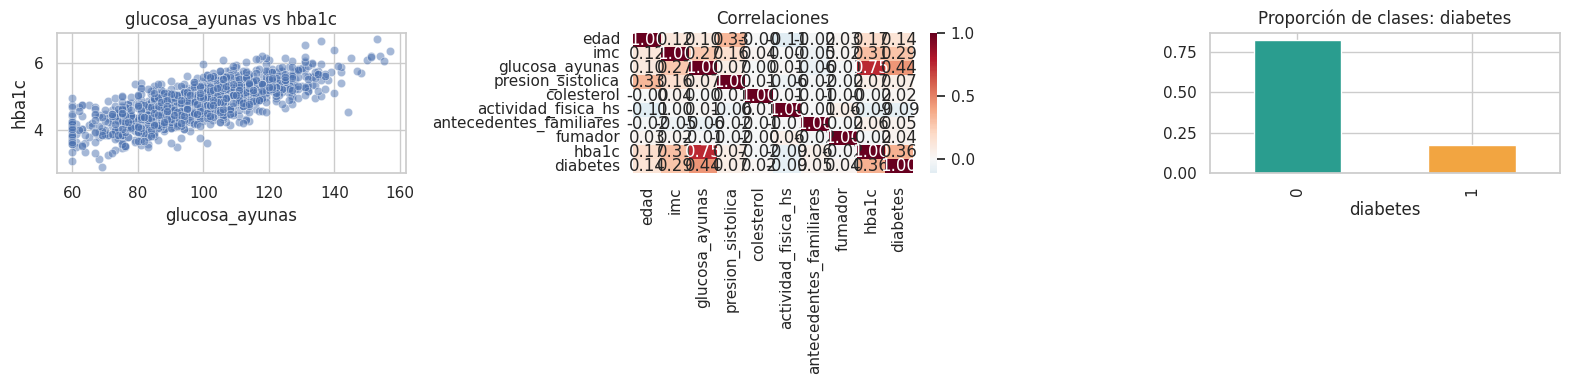

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="glucosa_ayunas", y="hba1c", alpha=.5, ax=ax[0]); ax[0].set_title("glucosa_ayunas vs hba1c")
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1]); ax[1].set_title("Correlaciones")
df["diabetes"].value_counts(normalize=True).plot.bar(ax=ax[2], color=["#2A9D8F", "#F2A541"]); ax[2].set_title("Proporción de clases: diabetes")
plt.tight_layout(); plt.show()

> **Para discutir:** ¿Qué variables parecen más relacionadas con `hba1c`? ¿Están balanceadas las clases de `diabetes`? ¿Qué consecuencia tiene eso para la *accuracy*?

## 2. Variables independientes (X), dependientes (y) y partición Train/Test
Tenemos **dos preguntas** sobre el mismo dataset:
- **Regresión** → ¿cuánto? → `hba1c` (continua, en % de hemoglobina glicosilada).
- **Clasificación** → ¿sí o no? → `diabetes` (binaria: paciente con diabetes).

Separamos un 20 % para el **test final** ("cofre bajo llave"). Con `stratify` conservamos la proporción de clases.

In [4]:
X = df.drop(columns=["hba1c", "diabetes"])
y_reg, y_clf = df["hba1c"], df["diabetes"]
X_train, X_test, yr_train, yr_test, yc_train, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de clase positiva en train / test:", round(yc_train.mean(), 3), "/", round(yc_test.mean(), 3))

Train: (960, 8) | Test: (240, 8)
Proporción de clase positiva en train / test: 0.173 / 0.171


## 3. Regresión lineal: predecir un número
$\hat{y} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$

Usamos un **Pipeline** para encadenar *imputar → escalar → modelo*. Así el escalador y el imputador se ajustan **solo con train** (evita *data leakage*).

Intercepto (β0): 4.81


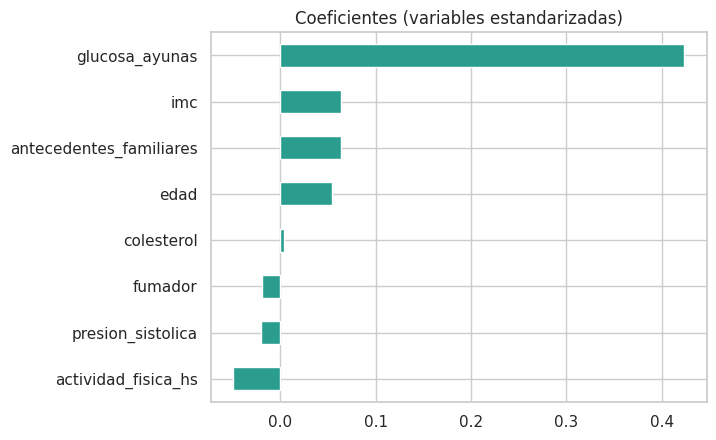

In [5]:
reg = Pipeline([("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("modelo", LinearRegression())])
reg.fit(X_train, yr_train)
pred = reg.predict(X_test)
coefs = pd.Series(reg.named_steps["modelo"].coef_, index=X.columns).sort_values()
print("Intercepto (β0):", round(reg.named_steps["modelo"].intercept_, 2))
coefs.plot.barh(title="Coeficientes (variables estandarizadas)", color="#2A9D8F"); plt.show()

> **Para discutir:** ¿Qué signo tiene cada coeficiente y qué significa? ¿Cuál es la variable con mayor peso? ¿Por qué podemos compararlos entre sí?

MAE=0.31 | MSE=0.15 | RMSE=0.39 | R²=0.581


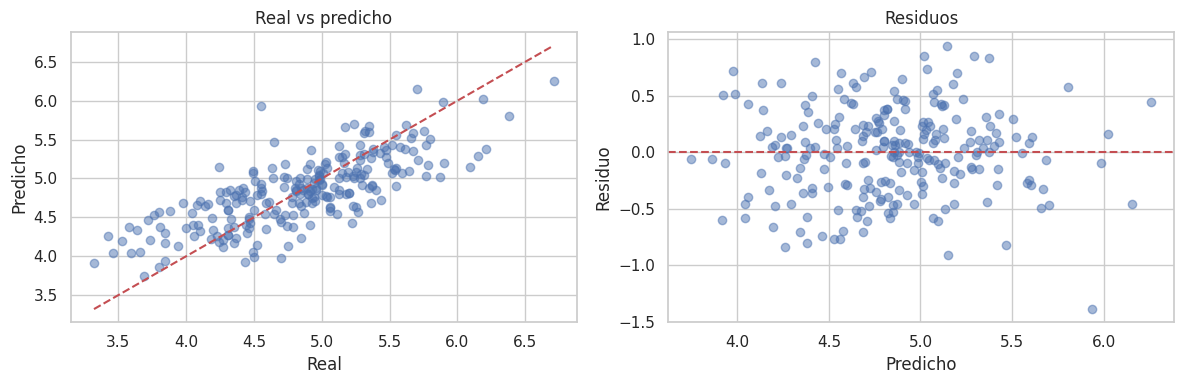

In [6]:
mae = mean_absolute_error(yr_test, pred)
mse = mean_squared_error(yr_test, pred)
print(f"MAE={mae:.2f} | MSE={mse:.2f} | RMSE={np.sqrt(mse):.2f} | R²={r2_score(yr_test, pred):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lim = [yr_test.min(), yr_test.max()]
ax[0].scatter(yr_test, pred, alpha=.5); ax[0].plot(lim, lim, "r--"); ax[0].set(xlabel="Real", ylabel="Predicho", title="Real vs predicho")
ax[1].scatter(pred, yr_test - pred, alpha=.5); ax[1].axhline(0, color="r", ls="--"); ax[1].set(xlabel="Predicho", ylabel="Residuo", title="Residuos")
plt.tight_layout(); plt.show()

## 4. ¿Cómo aprende? Descenso del gradiente "a mano"
Regresión simple con **una** variable estandarizada. Repetimos: predecir → medir el error (MSE) → mover $\beta_0,\beta_1$ en la dirección que baja la pérdida. `lr` es la **tasa de aprendizaje** (un hiperparámetro).

Descenso del gradiente: β0=4.82  β1=0.44  | MSE final=0.1
scikit-learn          : β0=4.82  β1=0.44


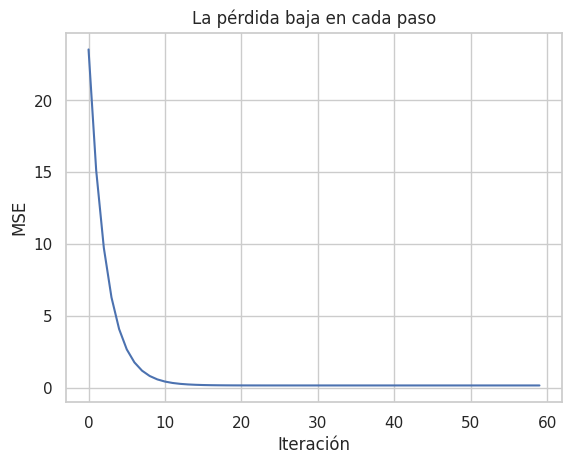

In [7]:
d = df[["glucosa_ayunas", "hba1c"]].dropna()
x = ((d["glucosa_ayunas"] - d["glucosa_ayunas"].mean()) / d["glucosa_ayunas"].std()).values
t = d["hba1c"].values
b0, b1, lr, hist = 0.0, 0.0, 0.1, []
for epoch in range(60):
    err = (b0 + b1 * x) - t
    hist.append(np.mean(err ** 2))            # pérdida: MSE
    b0 -= lr * 2 * err.mean()                 # gradiente respecto de β0
    b1 -= lr * 2 * (err * x).mean()           # gradiente respecto de β1
chk = LinearRegression().fit(x.reshape(-1, 1), t)
print(f"Descenso del gradiente: β0={b0:.2f}  β1={b1:.2f}  | MSE final={hist[-1]:.1f}")
print(f"scikit-learn          : β0={chk.intercept_:.2f}  β1={chk.coef_[0]:.2f}")
plt.plot(hist); plt.xlabel("Iteración"); plt.ylabel("MSE"); plt.title("La pérdida baja en cada paso"); plt.show()

> **Probá:** cambiá `lr` a `0.001` y luego a `1.1`. ¿Qué pasa con la curva de pérdida? ¿Por qué?

## 5. Regresión logística: predecir una probabilidad
$p = \dfrac{1}{1+e^{-z}}$ con $z = \beta_0 + \beta_1 x_1 + \dots$ (función **sigmoide**). Pasamos de probabilidad a clase con un **umbral** (por defecto 0.5).

Primeras 8 probabilidades: [0.02 0.05 0.34 0.02 0.04 0.01 0.05 0.45]


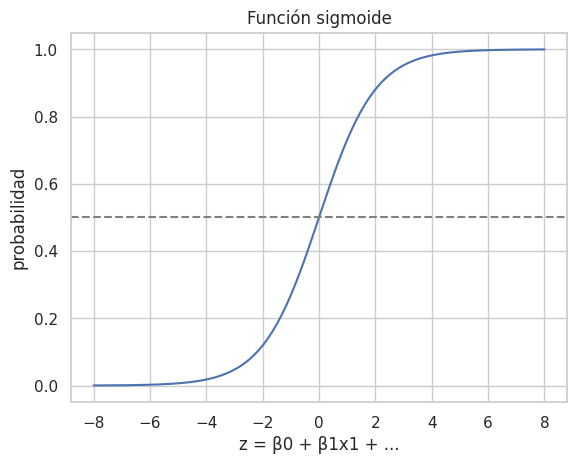

In [8]:
clf_log = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("modelo", LogisticRegression(max_iter=1000))])
clf_log.fit(X_train, yc_train)
proba = clf_log.predict_proba(X_test)[:, 1]
print("Primeras 8 probabilidades:", proba[:8].round(2))
z = np.linspace(-8, 8, 200)
plt.plot(z, 1 / (1 + np.exp(-z))); plt.axhline(.5, color="gray", ls="--")
plt.title("Función sigmoide"); plt.xlabel("z = β0 + β1x1 + ..."); plt.ylabel("probabilidad"); plt.show()

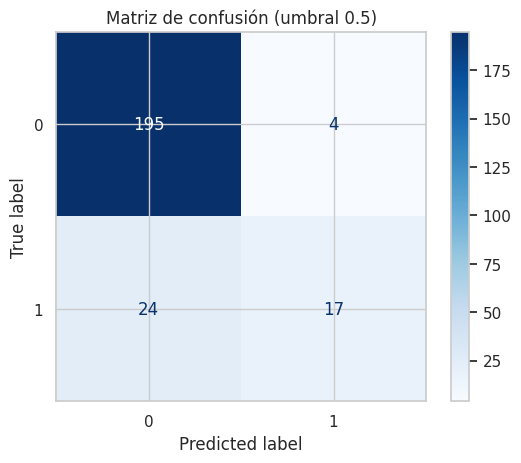

              precision    recall  f1-score   support

           0      0.890     0.980     0.933       199
           1      0.810     0.415     0.548        41

    accuracy                          0.883       240
   macro avg      0.850     0.697     0.741       240
weighted avg      0.877     0.883     0.867       240

AUC: 0.879 | Log Loss: 0.305
Accuracy de un modelo 'tonto' que siempre dice 0: 0.829


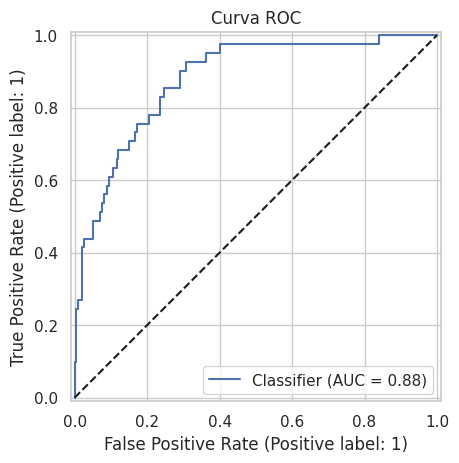

In [9]:
y_pred = (proba >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(yc_test, y_pred, cmap="Blues"); plt.title("Matriz de confusión (umbral 0.5)"); plt.show()
print(classification_report(yc_test, y_pred, digits=3))
print("AUC:", round(roc_auc_score(yc_test, proba), 3), "| Log Loss:", round(log_loss(yc_test, proba), 3))
print("Accuracy de un modelo 'tonto' que siempre dice 0:", round((yc_test == 0).mean(), 3))
RocCurveDisplay.from_predictions(yc_test, proba); plt.plot([0, 1], [0, 1], "k--"); plt.title("Curva ROC"); plt.show()

> **Para discutir:** Compará la *accuracy* con la del modelo "tonto". ¿Qué clase es la que más nos importa detectar? ¿Qué duele más: un falso positivo o un falso negativo?

### Efecto del umbral
Bajar el umbral atrapa más positivos (sube el **recall**) pero genera más falsas alarmas (baja la **precisión**).

In [10]:
rows = []
for thr in [0.1, 0.2, 0.3, 0.5, 0.7]:
    yp = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yc_test, yp).ravel()
    rows.append(dict(umbral=thr, TP=tp, FP=fp, FN=fn, TN=tn,
                     precision=tp / (tp + fp) if tp + fp else np.nan, recall=tp / (tp + fn)))
display(pd.DataFrame(rows).round(3))

,umbral,TP,FP,FN,TN,precision,recall
0,0.1,39,79,2,120,0.331,0.951
1,0.2,32,45,9,154,0.416,0.780
2,0.3,28,28,13,171,0.500,0.683
3,0.5,17,4,24,195,0.810,0.415
4,0.7,9,1,32,198,0.900,0.220


## 6. Ensembles: Bagging, Boosting y Stacking
- **Bagging** (Random Forest): muchos árboles independientes → baja la *varianza*.
- **Boosting** (Gradient Boosting): árboles secuenciales que corrigen errores → baja el *sesgo*.
- **Stacking**: modelos de familias distintas + un meta-modelo que decide.

In [11]:
imp = lambda: SimpleImputer(strategy="median")
modelos = {
    "LogReg": clf_log,
    "RandomForest (bagging)": Pipeline([("imp", imp()), ("m", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]),
    "GradientBoosting (boosting)": Pipeline([("imp", imp()), ("m", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
    "Stacking": Pipeline([("imp", imp()), ("m", StackingClassifier(
        estimators=[("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
                    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier())),
                    ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))],
        final_estimator=LogisticRegression(max_iter=1000)))]),
}
print("Modelos a comparar:", list(modelos))

Modelos a comparar: ['LogReg', 'RandomForest (bagging)', 'GradientBoosting (boosting)', 'Stacking']


## 7. Validación cruzada estratificada
Evaluamos cada modelo con **5 folds** sobre el set de *train* (el test sigue intacto). Miramos el **promedio** y la **desviación**: un buen modelo tiene promedio alto y desvío bajo.

,F1 medio,Desvío
LogReg,0.480,0.062
RandomForest (bagging),0.357,0.037
GradientBoosting (boosting),0.443,0.070
Stacking,0.419,0.049


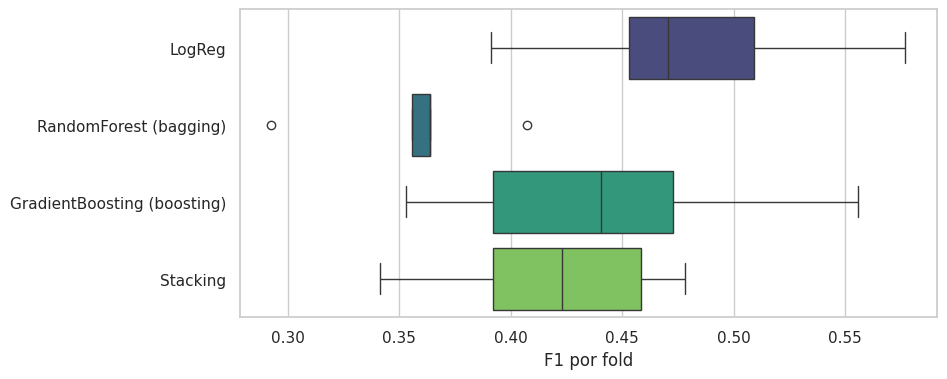

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
res = {nombre: cross_val_score(m, X_train, yc_train, cv=cv, scoring="f1") for nombre, m in modelos.items()}
resumen = pd.DataFrame({k: {"F1 medio": v.mean(), "Desvío": v.std()} for k, v in res.items()}).T.round(3)
display(resumen)
plt.figure(figsize=(9, 4)); sns.boxplot(data=pd.DataFrame(res), orient="h", palette="viridis")
plt.xlabel("F1 por fold"); plt.show()

> **Para discutir:** ¿Hay un ganador claro? ¿Alguno es inestable (desvío alto)? ¿Vale la pena la complejidad del ensemble frente a la regresión logística?

## 8. Ajuste de hiperparámetros con GridSearchCV
Probamos **todas las combinaciones** de una grilla; cada una se evalúa con validación cruzada.

In [13]:
pipe_rf = Pipeline([("imp", imp()), ("m", RandomForestClassifier(random_state=RANDOM_STATE))])
param_grid = {"m__n_estimators": [100, 300],
              "m__max_depth": [3, 6, None],
              "m__min_samples_leaf": [1, 5]}
gs = GridSearchCV(pipe_rf, param_grid, cv=cv, scoring="f1", n_jobs=-1)
gs.fit(X_train, yc_train)
print("Combinaciones:", len(gs.cv_results_["params"]), "x 5 folds =", len(gs.cv_results_["params"]) * 5, "entrenamientos")
print("best_params_:", gs.best_params_)
print("best_score_ :", round(gs.best_score_, 3))
display(pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(5).round(3))

Combinaciones: 12 x 5 folds = 60 entrenamientos
best_params_: {'m__max_depth': None, 'm__min_samples_leaf': 1, 'm__n_estimators': 100}
best_score_ : 0.394


,params,mean_test_score,std_test_score
8,"{'m__max_depth': None, 'm__min_samples_leaf': ...",0.394,0.040
9,"{'m__max_depth': None, 'm__min_samples_leaf': ...",0.374,0.045
10,"{'m__max_depth': None, 'm__min_samples_leaf': ...",0.365,0.059
11,"{'m__max_depth': None, 'm__min_samples_leaf': ...",0.363,0.075
6,"{'m__max_depth': 6, 'm__min_samples_leaf': 5, ...",0.354,0.067


## 9. Evaluación final: se abre el "cofre" **una sola vez**
Usamos `best_estimator_` (ya reentrenado con todo el train) y lo probamos contra el test que nunca vio.

              precision    recall  f1-score   support

           0      0.889     0.965     0.925       199
           1      0.708     0.415     0.523        41

    accuracy                          0.871       240
   macro avg      0.799     0.690     0.724       240
weighted avg      0.858     0.871     0.857       240

AUC en test: 0.844


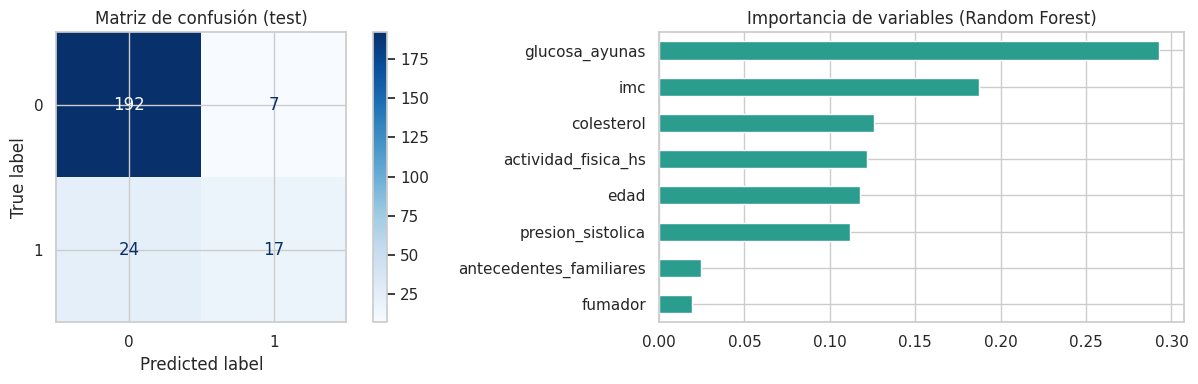

In [14]:
mejor = gs.best_estimator_
yp = mejor.predict(X_test); pp = mejor.predict_proba(X_test)[:, 1]
print(classification_report(yc_test, yp, digits=3))
print("AUC en test:", round(roc_auc_score(yc_test, pp), 3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ConfusionMatrixDisplay.from_predictions(yc_test, yp, cmap="Blues", ax=ax[0]); ax[0].set_title("Matriz de confusión (test)")
pd.Series(mejor.named_steps["m"].feature_importances_, index=X.columns).sort_values().plot.barh(ax=ax[1], color="#2A9D8F")
ax[1].set_title("Importancia de variables (Random Forest)"); plt.tight_layout(); plt.show()

## 🧑‍🏫 Guía de respuestas para el docente (con la semilla `random_state=42`)
- **Regresión:** R² ≈ 0.58, RMSE ≈ 0.39 puntos de HbA1c. La variable de mayor peso es `glucosa_ayunas` (coeficiente positivo); `actividad_fisica_hs` tiene signo negativo.
- **Trampa de la accuracy:** la regresión logística llega a ≈ 0.88 de accuracy, pero un modelo "tonto" que siempre dice *sin diabetes* ya logra ≈ 0.83. El **recall de la clase positiva es solo ≈ 0.41** con umbral 0.5: se escapan más de la mitad de los pacientes con diabetes.
- **Umbral:** bajar a 0.2–0.3 sube mucho el recall (≈ 0.78–0.68) a costa de precisión. Si el costo de un falso negativo es alto (tamizaje médico), conviene un umbral bajo.
- **Ensembles:** en validación cruzada la regresión logística (F1 ≈ 0.48) supera a Random Forest (≈ 0.36), Boosting (≈ 0.44) y Stacking (≈ 0.42): con pocos datos y relaciones casi lineales, **el modelo más complejo no siempre gana**.
- **GridSearchCV:** mejora marginal; el F1 sigue limitado por el desbalance. Siguiente paso posible: `class_weight="balanced"` o ajustar el umbral.
- **Test final:** AUC ≈ 0.84–0.88. Recordar que el test se abre **una sola vez**.